# Statistical learning for air-quality estimation

**Gabriel Trabelsi | Selected academic project**

Estimate four reference pollutant concentrations from five sensor responses and three weather variables. This notebook combines the exploratory analysis and modelling from the original submission, with its saved figures and numerical outputs.

**Reading guide:** data and temporal structure; linear baselines; kernel ridge regression; neural networks; interpretation and residuals.

The original experiments are exploratory. The final chronological partition was inspected repeatedly during model comparison; preprocessing also precedes the inner cross-validation. The scores below describe these experiments and should not be read as an independent final benchmark. See [methodology notes](../docs/methodology.md).

## 1. Data and exploratory analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Chargement — séparateur ';', décimale ','
from pathlib import Path

# Locate the dataset from the repository root or the notebooks directory.
DATA_PATH = next((p for p in [Path("data/AirQualityUCI.csv"), Path("../data/AirQualityUCI.csv")] if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place AirQualityUCI.csv in the repository data/ directory.")
df = pd.read_csv(DATA_PATH, sep=";", decimal=",")

# Suppression des colonnes vides en fin de ligne
df = df.dropna(axis=1, how="all")

print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")
df.head()


Dimensions : 9471 lignes × 15 colonnes


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


### 1.1 Variables

The targets are `CO(GT)`, `C6H6(GT)`, `NOx(GT)` and `NO2(GT)`. Predictors are the five `PT08` sensor responses plus temperature (`T`), relative humidity (`RH`) and absolute humidity (`AH`). Reference concentrations and sensor responses are different measurements; sensor labels describe nominal sensitivity.

Source: [UCI Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality), S. Vito, DOI [10.24432/C59K5F](https://doi.org/10.24432/C59K5F).

In [ ]:
# Types et statistiques de base
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), object(2)
memory usage: 1.1+ MB


In [ ]:
df.describe().round(2)


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00
mean,-34.21,1048.99,-159.09,1.87,894.60,168.62,794.99,58.15,1391.48,975.07,9.78,39.49,-6.84
std,77.66,329.83,139.79,41.38,342.33,257.43,321.99,126.94,467.21,456.94,43.20,51.22,38.98
min,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00
25%,0.60,921.00,-200.00,4.00,711.00,50.00,637.00,53.00,1185.00,700.00,10.90,34.10,0.69
50%,1.50,1053.00,-200.00,7.90,895.00,141.00,794.00,96.00,1446.00,942.00,17.20,48.60,0.98
75%,2.60,1221.00,-200.00,13.60,1105.00,284.00,960.00,133.00,1662.00,1255.00,24.10,61.90,1.30
max,11.90,2040.00,1189.00,63.70,2214.00,1479.00,2683.00,340.00,2775.00,2523.00,44.60,88.70,2.23


### 1.2 Missing values

The value `-200` denotes missing data. Empty trailing rows are removed. `NMHC(GT)` is excluded because it is mostly missing and is not one of the selected sensor predictors. Complete-case filtering produces 6,941 observations in the saved run; this filtering can change the distribution of the data.

In [ ]:
# Suppression des lignes entièrement vides (fin de fichier)
df = df.dropna(subset=["Date"])

# Colonnes numériques (hors Date/Time)
num_cols = df.columns.drop(["Date", "Time"])

# Remplacement de -200 par NaN
df[num_cols] = df[num_cols].replace(-200, np.nan)

# Pourcentage de valeurs manquantes par colonne
missing_pct = (df[num_cols].isna().sum() / len(df) * 100).round(1)
missing_pct.sort_values(ascending=False)


NMHC(GT)         90.2
CO(GT)           18.0
NOx(GT)          17.5
NO2(GT)          17.5
PT08.S1(CO)       3.9
PT08.S2(NMHC)     3.9
C6H6(GT)          3.9
PT08.S3(NOx)      3.9
PT08.S4(NO2)      3.9
PT08.S5(O3)       3.9
T                 3.9
RH                3.9
AH                3.9
dtype: float64

In [ ]:
# NMHC(GT) : ~90% de valeurs manquantes → suppression justifiée car :
#   1. Imputer 90% de NaN produirait du bruit, pas de l'information
#   2. Garder la colonne et supprimer les lignes NaN réduirait le dataset à ~700 lignes
#   3. C'est une mesure de référence (GT), pas un capteur, ce n'est donc pas l'objectif du tp.
df = df.drop(columns=["NMHC(GT)"])
num_cols = num_cols.drop("NMHC(GT)")

df = df.dropna(subset=num_cols)
print(f"Dimensions après nettoyage : {df.shape[0]} lignes × {df.shape[1]} colonnes")


Dimensions après nettoyage : 6941 lignes × 14 colonnes


### 1.3 Target distributions

Histograms and boxplots describe the range and asymmetry of the four reference concentrations.

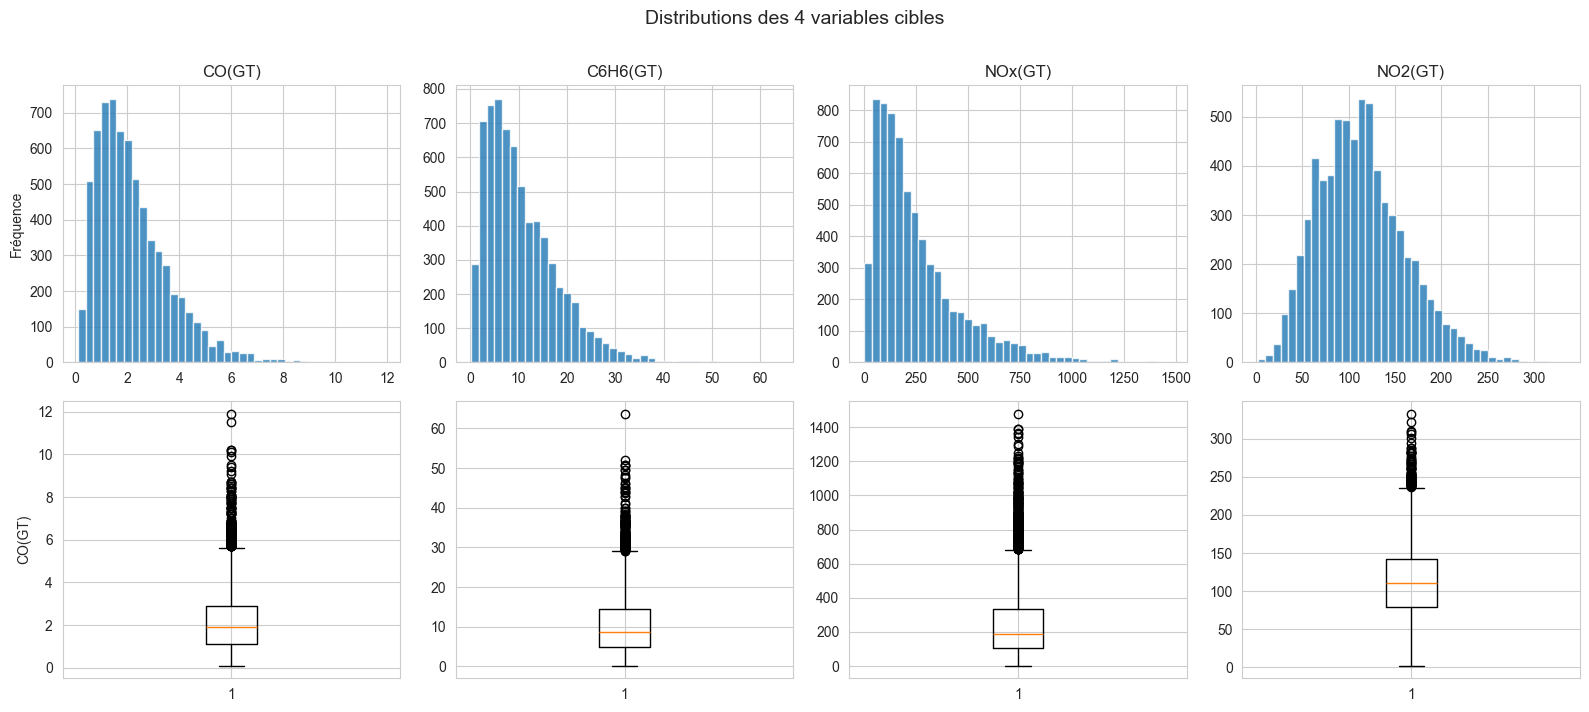

In [ ]:
targets = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, col in enumerate(targets):
    # Histogramme
    axes[0, i].hist(df[col], bins=40, edgecolor="white", alpha=0.8)
    axes[0, i].set_title(col)
    axes[0, i].set_ylabel("Fréquence" if i == 0 else "")
    # Boxplot
    axes[1, i].boxplot(df[col], vert=True)
    axes[1, i].set_ylabel(col if i == 0 else "")

fig.suptitle("Distributions des 4 variables cibles", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


The distributions have long upper tails. Errors at high concentrations deserve separate attention from average prediction error.

### 1.4 Sensor and weather distributions

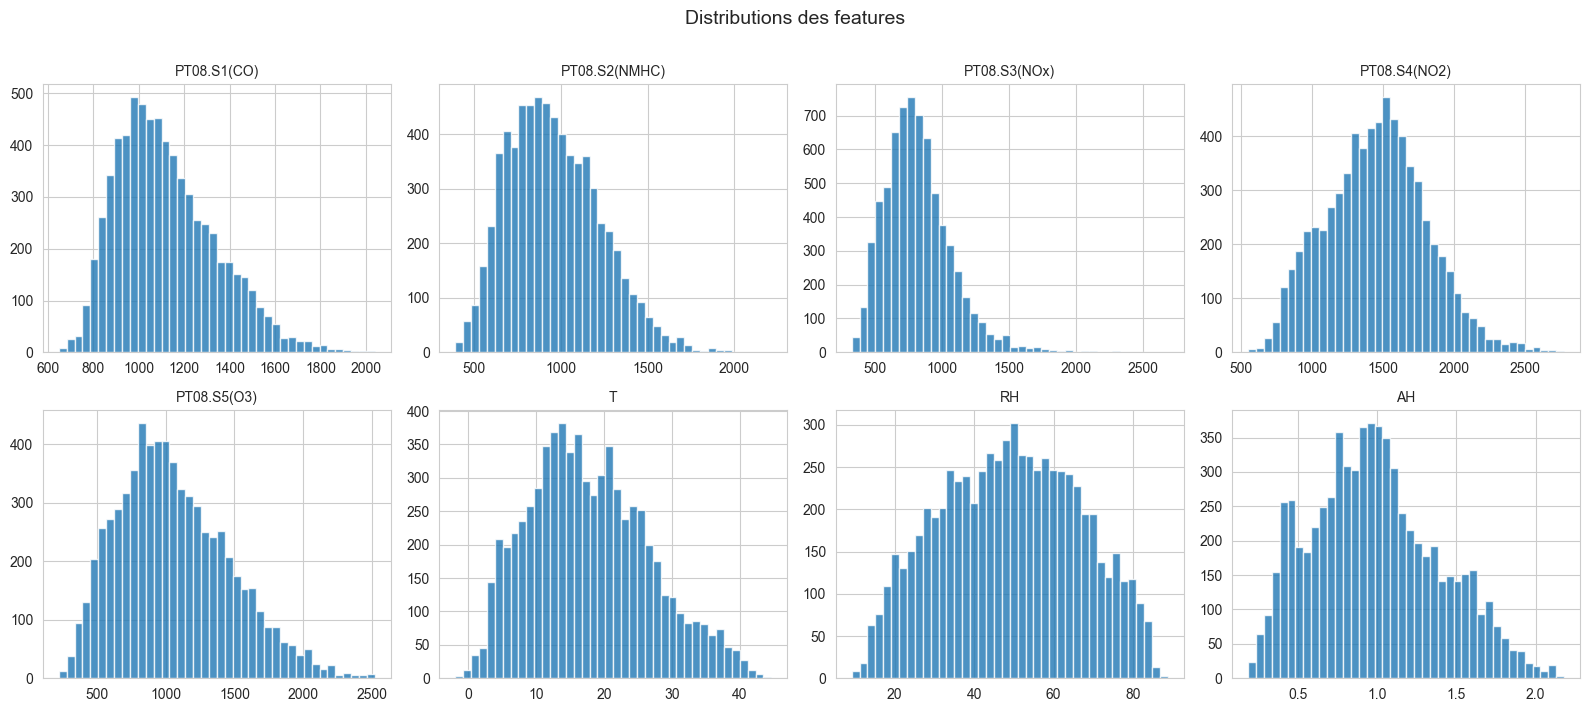

In [ ]:
features = [c for c in num_cols if c not in targets]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()

for i, col in enumerate(features):
    axes[i].hist(df[col], bins=40, edgecolor="white", alpha=0.8)
    axes[i].set_title(col, fontsize=10)

for j in range(len(features), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Distributions des features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


Sensor responses differ substantially in scale. The modelling section standardizes predictors using the training partition.

### 1.5 Correlations

Pairwise correlations describe linear associations. They do not establish causal influence or exclude nonlinear relationships.

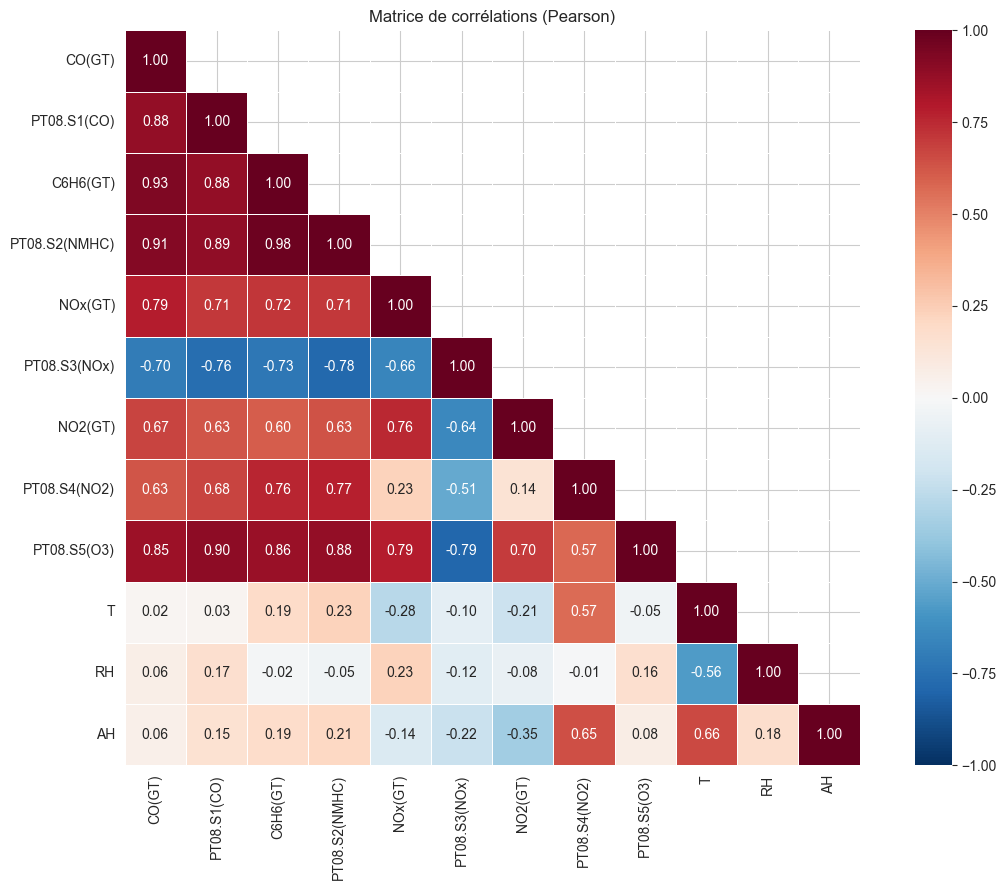

In [ ]:
corr = df[num_cols].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matrice de corrélations (Pearson)")
plt.tight_layout()
plt.show()


Several sensors are correlated with each other. This matters when interpreting regression coefficients and feature-importance estimates.

### 1.6 Sensor-target relationships

The scatter plots examine the relation between each selected target and a nominally associated sensor.

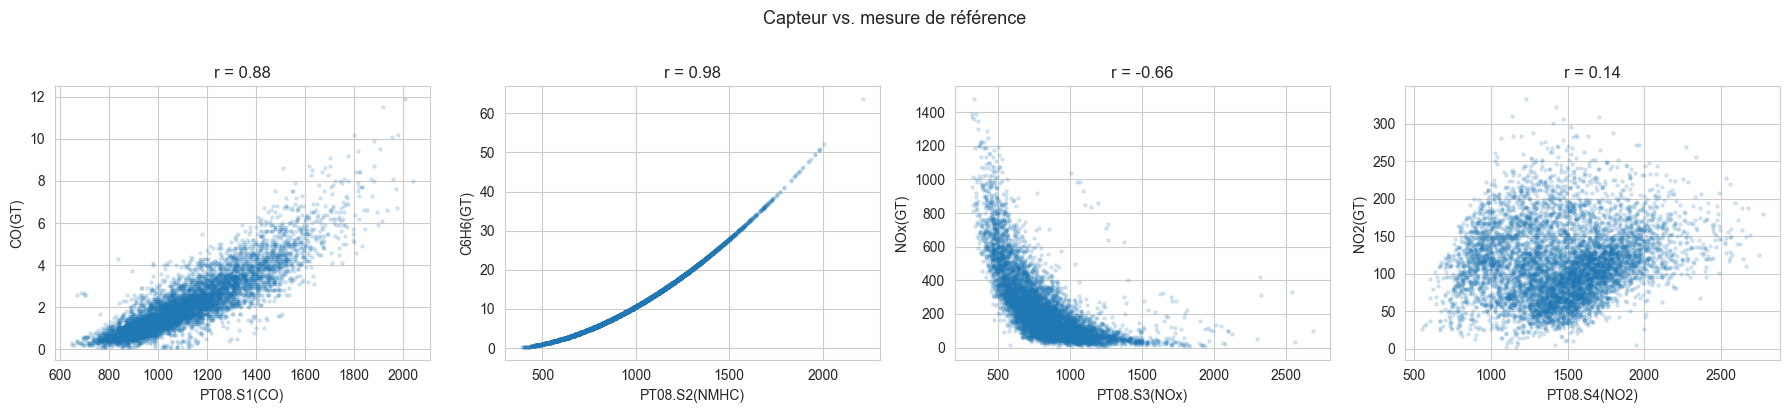

In [ ]:
# Chaque cible vs son capteur correspondant
pairs = [
    ("PT08.S1(CO)", "CO(GT)"),
    ("PT08.S2(NMHC)", "C6H6(GT)"),
    ("PT08.S3(NOx)", "NOx(GT)"),
    ("PT08.S4(NO2)", "NO2(GT)"),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, (feat, tgt) in enumerate(pairs):
    axes[i].scatter(df[feat], df[tgt], alpha=0.15, s=5)
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel(tgt)
    r = df[feat].corr(df[tgt])
    axes[i].set_title(f"r = {r:.2f}")

fig.suptitle("Capteur vs. mesure de référence", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


The sensor-target relationships differ across pollutants. A strong association for one target does not imply that the same model will work equally well for another.

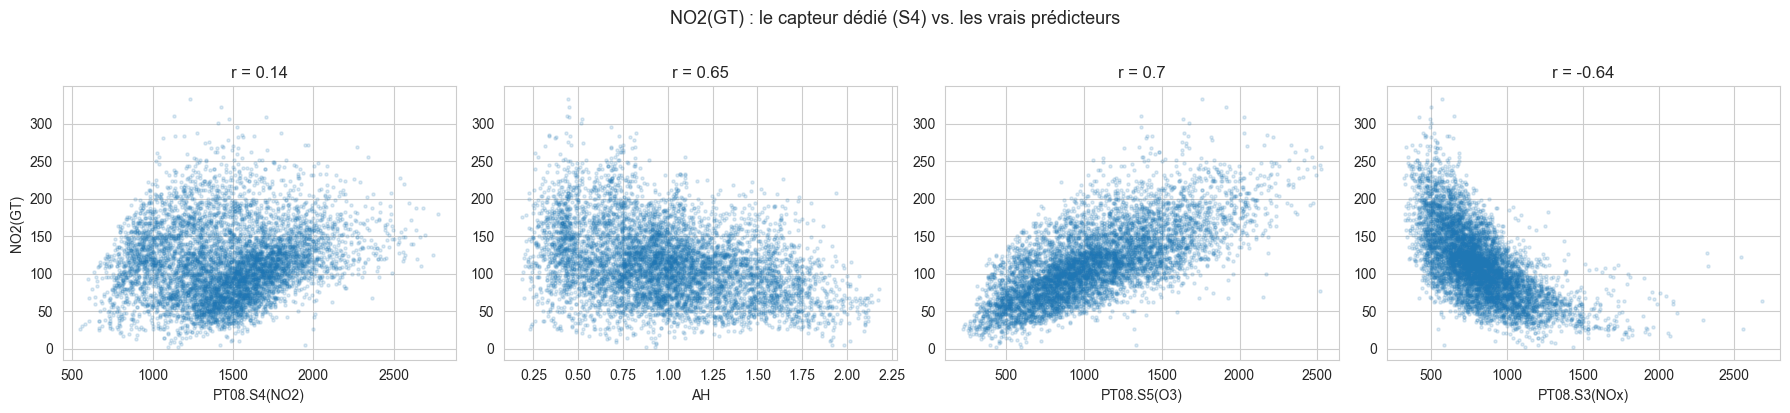

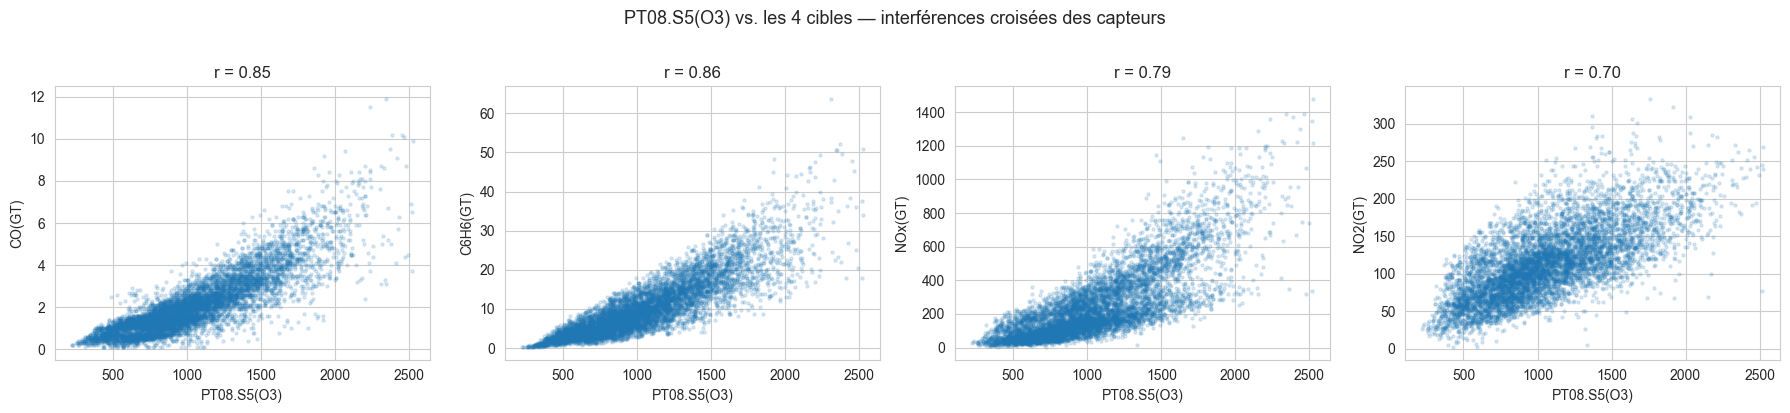

In [ ]:
# --- Relations complémentaires ---

# Plot 1 : Qui prédit NO2 le mieux ? (la cible la plus difficile)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
no2_friends = [("PT08.S4(NO2)", 0.14), ("AH", 0.65), ("PT08.S5(O3)", 0.70), ("PT08.S3(NOx)", -0.64)]
for i, (feat, r) in enumerate(no2_friends):
    axes[i].scatter(df[feat], df["NO2(GT)"], alpha=0.15, s=5)
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel("NO2(GT)" if i == 0 else "")
    axes[i].set_title(f"r = {r}")
fig.suptitle("NO2(GT) : le capteur dédié (S4) vs. les vrais prédicteurs", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Plot 2 : PT08.S5(O3) — un capteur d'ozone qui prédit tout ?
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, tgt in enumerate(targets):
    axes[i].scatter(df["PT08.S5(O3)"], df[tgt], alpha=0.15, s=5)
    axes[i].set_xlabel("PT08.S5(O3)")
    axes[i].set_ylabel(tgt)
    r = df["PT08.S5(O3)"].corr(df[tgt])
    axes[i].set_title(f"r = {r:.2f}")
fig.suptitle("PT08.S5(O3) vs. les 4 cibles — interférences croisées des capteurs", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


These additional plots inspect individual predictors of NO2. Predictor choice in the modelling study is retained from the original work.

### 1.7 Temporal evolution

Dates and times are combined to inspect changes in concentration over the observation period.

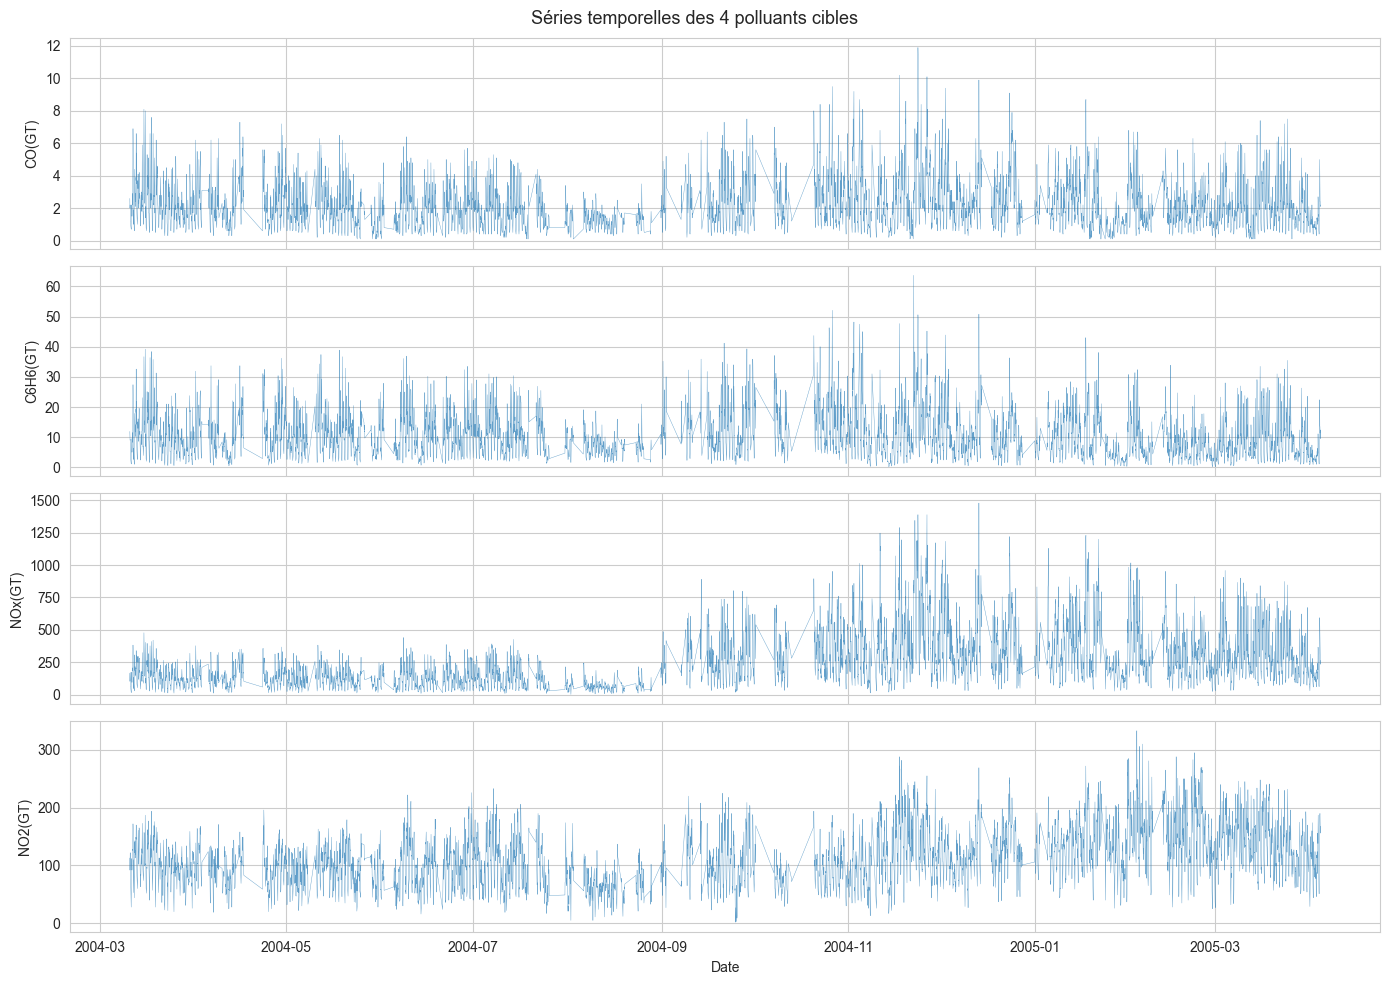

In [ ]:
# Construction d'un index datetime
df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"],
                                 format="%d/%m/%Y %H.%M.%S")

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for i, col in enumerate(targets):
    axes[i].plot(df["Datetime"], df[col], linewidth=0.3, alpha=0.7)
    axes[i].set_ylabel(col)

axes[-1].set_xlabel("Date")
fig.suptitle("Séries temporelles des 4 polluants cibles", fontsize=13)
plt.tight_layout()
plt.show()


### 1.8 Average daily profiles

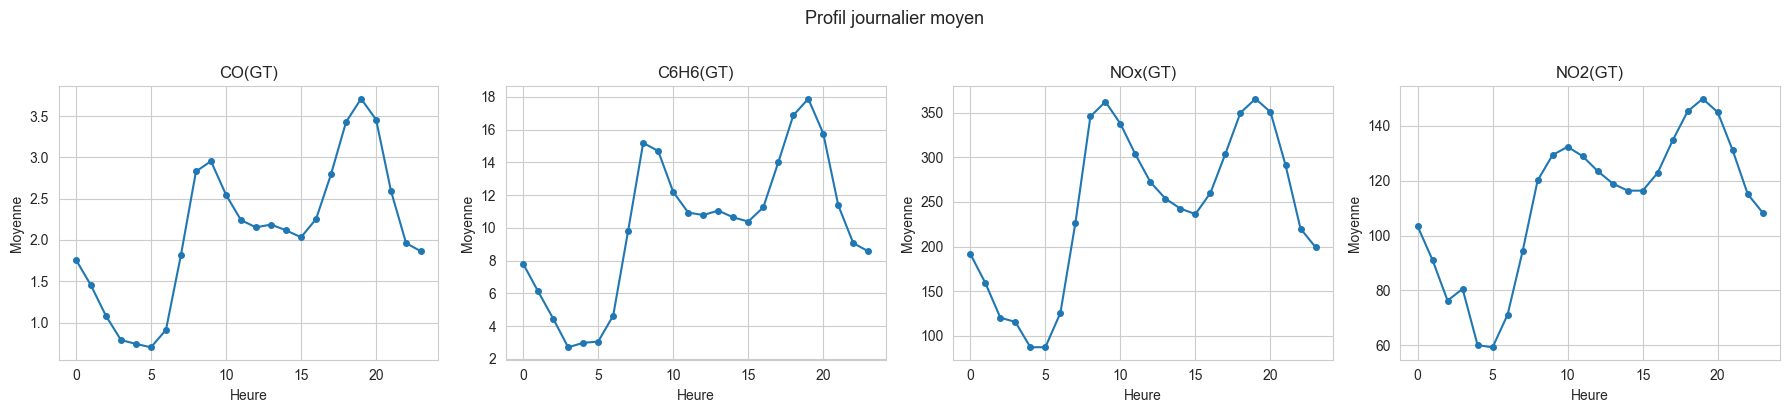

In [ ]:
df["Hour"] = df["Datetime"].dt.hour

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(targets):
    hourly = df.groupby("Hour")[col].mean()
    axes[i].plot(hourly.index, hourly.values, marker="o", markersize=4)
    axes[i].set_title(col)
    axes[i].set_xlabel("Heure")
    axes[i].set_ylabel("Moyenne")

fig.suptitle("Profil journalier moyen", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


Averages by hour reveal temporal structure. They are descriptive summaries of the available observations, not forecasts.

### 1.9 Monthly profiles

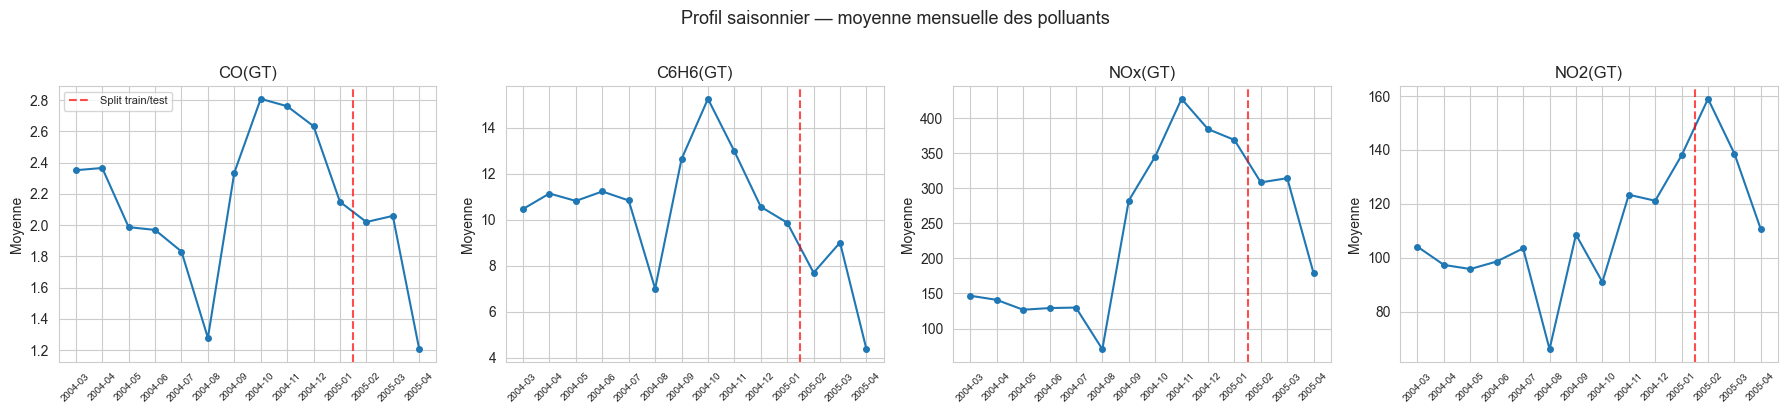

In [ ]:
df["Month"] = df["Datetime"].dt.to_period("M")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(targets):
    monthly = df.groupby("Month")[col].mean()
    axes[i].plot(range(len(monthly)), monthly.values, marker="o", markersize=4)
    axes[i].set_title(col)
    axes[i].set_xticks(range(len(monthly)))
    axes[i].set_xticklabels([str(m) for m in monthly.index], rotation=45, fontsize=7)
    axes[i].set_ylabel("Moyenne")
    # Ligne de séparation train/test (80%)
    split_idx = int(0.8 * len(monthly))
    axes[i].axvline(x=split_idx - 0.5, color="red", linestyle="--", alpha=0.7, label="Split train/test")
    if i == 0:
        axes[i].legend(fontsize=8)

fig.suptitle("Profil saisonnier — moyenne mensuelle des polluants", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


Monthly averages differ. A chronological training/evaluation split therefore also changes the periods represented in each partition.

### 1.10 Exploratory synthesis

The data combine correlated sensors, missing measurements, skewed concentrations and temporal variation. These observations motivate the comparison of linear and nonlinear regressors and the inspection of residuals.

### 1.11 Regression task

For each observation, $x_i=(S1_i,S2_i,S3_i,S4_i,S5_i,T_i,RH_i,AH_i)\in\mathbb{R}^8$. Four separate functions $f_k:\mathbb{R}^8\to\mathbb{R}$ estimate the reference concentrations. The objective is simultaneous sensor-based estimation; no future forecasting horizon is defined.

## 2. Linear baselines

Ordinary least squares minimizes squared residuals. Ridge adds an $\ell_2$ penalty on coefficients. The study compares a one-sensor baseline with models using all eight predictors.

### 2.1 Chronological split and scaling

The original code uses the first 80% of cleaned rows for training and the remaining 20% for evaluation: 5,552 and 1,389 observations. The scaler is fitted on the outer training partition. Its placement before inner cross-validation is documented in the methodology notes.

In [ ]:
from sklearn.preprocessing import StandardScaler

# --- Définition features / cibles ---
targets = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
features = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)",
            "PT08.S5(O3)", "T", "RH", "AH"]

X = df[features].values
ys = {t: df[t].values for t in targets}

# --- Train / Test split (80/20, chronologique) ---
n = len(X)
split = int(0.8 * n)

X_train, X_test = X[:split], X[split:]
ys_train = {t: y[:split] for t, y in ys.items()}
ys_test  = {t: y[split:] for t, y in ys.items()}

# --- Standardisation (fit sur train uniquement) ---
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f"Train : {X_train_s.shape[0]} échantillons")
print(f"Test  : {X_test_s.shape[0]} échantillons")
print(f"Features : {features}")
print(f"Cibles : {targets}")


Train : 5552 échantillons
Test  : 1389 échantillons
Features : ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Cibles : ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']


### 2.2 OLS and ridge results

The table reports R², RMSE and MAE from the saved experiment. RidgeCV uses its default internal validation procedure.

In [ ]:
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

dedicated_sensor = {
    "CO(GT)": 0,      # S1
    "C6H6(GT)": 1,    # S2
    "NOx(GT)": 2,     # S3
    "NO2(GT)": 3,     # S4
}

alphas = [10**(i-3) for i in range(8)]  # 0.001 à 10000
results = []

for target in targets:
    sensor_idx = dedicated_sensor[target]

    # OLS univarié (capteur dédié seul)
    ols_uni = LinearRegression()
    ols_uni.fit(X_train_s[:, [sensor_idx]], ys_train[target])
    y_pred_uni = ols_uni.predict(X_test_s[:, [sensor_idx]])

    # OLS multivarié (8 features)
    ols_multi = LinearRegression()
    ols_multi.fit(X_train_s, ys_train[target])
    y_pred_multi = ols_multi.predict(X_test_s)

    # Ridge multivarié (8 features)
    ridge = RidgeCV(alphas=alphas)
    ridge.fit(X_train_s, ys_train[target])
    y_pred_ridge = ridge.predict(X_test_s)

    for name, y_pred in [("OLS 1 feat", y_pred_uni), ("OLS 8 feat", y_pred_multi), ("Ridge 8 feat", y_pred_ridge)]:
        results.append({
            "Cible": target,
            "Méthode": name,
            "R²": r2_score(ys_test[target], y_pred),
            "RMSE": np.sqrt(mean_squared_error(ys_test[target], y_pred)),
            "MAE": mean_absolute_error(ys_test[target], y_pred),
        })

pd.DataFrame(results).set_index(["Cible", "Méthode"]).round(4)


R²      RMSE      MAE
Cible    Méthode                                
CO(GT)   OLS 1 feat    0.6848    0.7343   0.5629
         OLS 8 feat    0.8605    0.4886   0.3455
         Ridge 8 feat  0.8605    0.4885   0.3455
C6H6(GT) OLS 1 feat    0.9529    1.3680   1.0447
         OLS 8 feat    0.9429    1.5064   1.1287
         Ridge 8 feat  0.9429    1.5061   1.1283
NOx(GT)  OLS 1 feat    0.5594  126.4155  89.2845
         OLS 8 feat    0.8336   77.6799  52.3834
         Ridge 8 feat  0.8339   77.6209  52.3544
NO2(GT)  OLS 1 feat   -0.9939   72.8158  59.8106
         OLS 8 feat    0.5018   36.3975  26.7123
         Ridge 8 feat  0.5019   36.3931  26.7071

### 2.3 Ridge sensitivity

The following exploratory sweep varies the regularization strength and displays both predictive scores and coefficient paths.

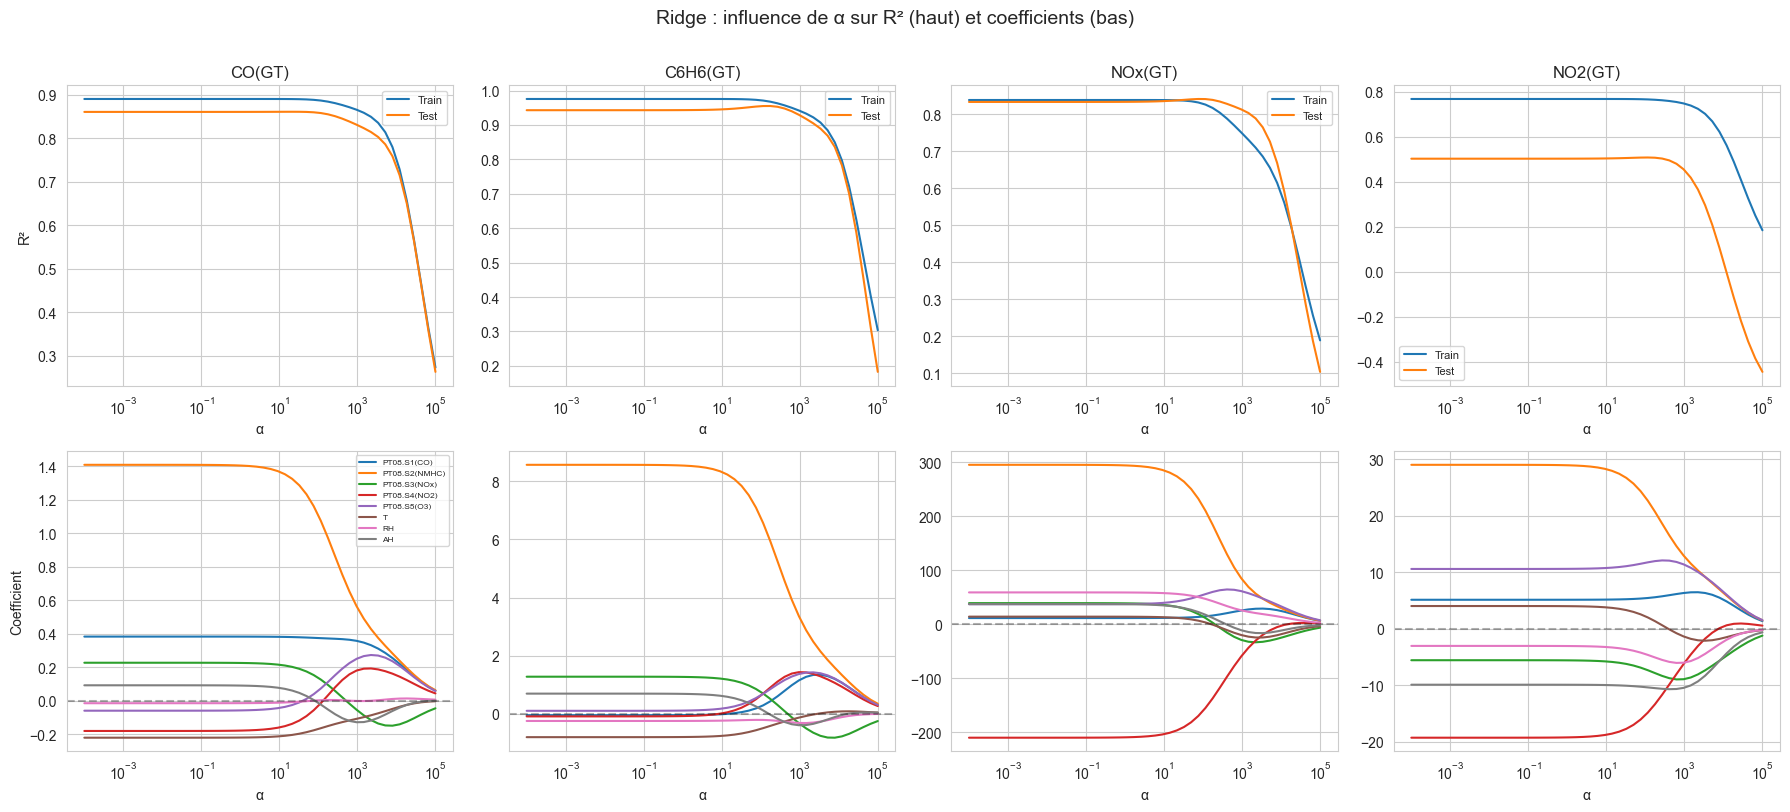

In [ ]:
from sklearn.linear_model import Ridge
import seaborn as sns

alphas_range = np.logspace(-4, 5, 50)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for j, target in enumerate(targets):
    r2_train_list, r2_test_list = [], []
    coefs_list = []

    for a in alphas_range:
        ridge = Ridge(alpha=a)
        ridge.fit(X_train_s, ys_train[target])
        r2_train_list.append(r2_score(ys_train[target], ridge.predict(X_train_s)))
        r2_test_list.append(r2_score(ys_test[target], ridge.predict(X_test_s)))
        coefs_list.append(ridge.coef_)

    # R² vs alpha
    axes[0, j].plot(alphas_range, r2_train_list, label="Train")
    axes[0, j].plot(alphas_range, r2_test_list, label="Test")
    axes[0, j].set_xscale("log")
    axes[0, j].set_xlabel("α")
    axes[0, j].set_ylabel("R²" if j == 0 else "")
    axes[0, j].set_title(target)
    axes[0, j].legend(fontsize=8)

    # Coefficients vs alpha
    coefs_array = np.array(coefs_list)
    for k in range(coefs_array.shape[1]):
        axes[1, j].plot(alphas_range, coefs_array[:, k], label=features[k] if j == 0 else None)
    axes[1, j].set_xscale("log")
    axes[1, j].set_xlabel("α")
    axes[1, j].set_ylabel("Coefficient" if j == 0 else "")
    axes[1, j].axhline(y=0, color="black", linestyle="--", alpha=0.3)

if axes[1, 0].get_legend() is None:
    axes[1, 0].legend(fontsize=6, loc="best")

fig.suptitle("Ridge : influence de α sur R² (haut) et coefficients (bas)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


Across the displayed range, coefficient shrinkage can be visible before prediction quality changes substantially. A large observation-to-feature ratio alone does not establish good matrix conditioning.

### 2.4 Coefficients by target

Coefficients refer to standardized predictors. Correlated variables complicate their interpretation.

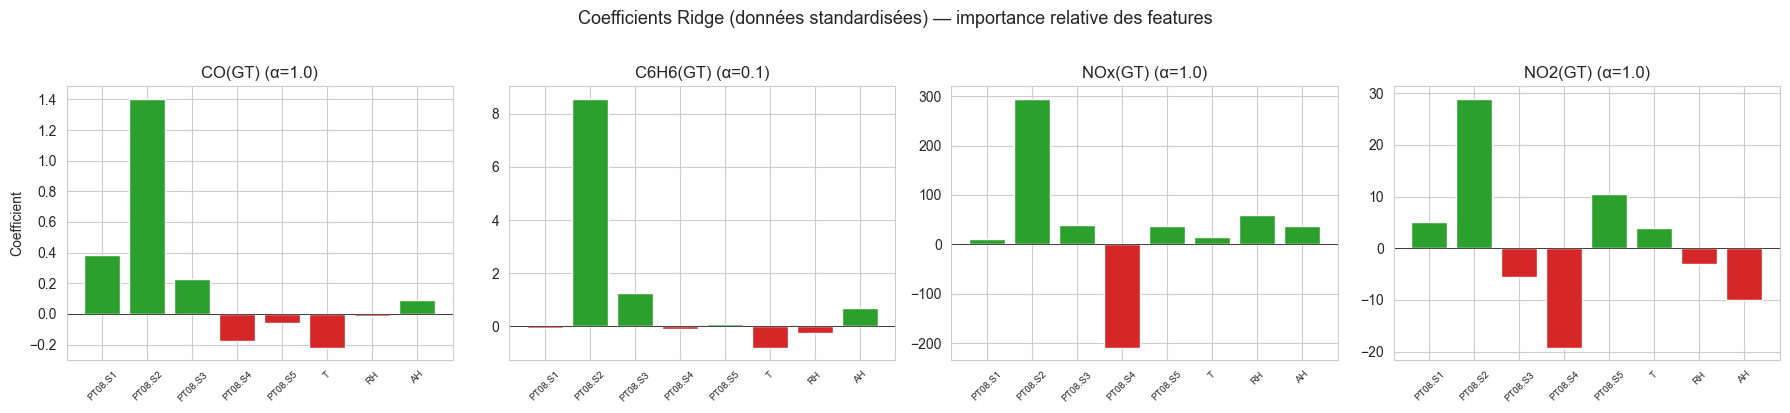

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
x_pos = np.arange(len(features))

for j, target in enumerate(targets):
    ridge = RidgeCV(alphas=[10**(i-3) for i in range(8)])
    ridge.fit(X_train_s, ys_train[target])
    colors = ["#d62728" if c < 0 else "#2ca02c" for c in ridge.coef_]
    axes[j].bar(x_pos, ridge.coef_, color=colors)
    axes[j].set_xticks(x_pos)
    axes[j].set_xticklabels([f.split("(")[0] for f in features], rotation=45, fontsize=7)
    axes[j].set_title(f"{target} (α={ridge.alpha_})")
    axes[j].set_ylabel("Coefficient" if j == 0 else "")
    axes[j].axhline(y=0, color="black", linewidth=0.5)

fig.suptitle("Coefficients Ridge (données standardisées) — importance relative des features", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


The coefficient profiles differ by pollutant. They describe the fitted linear models and should not be interpreted as causal effects.

## 3. Kernel ridge regression

An RBF kernel allows nonlinear relationships through $K(x,x')=\exp(-\gamma\|x-x'\|^2)$. The original search varies regularization $\alpha$ and kernel parameter $\gamma$ with `TimeSeriesSplit(n_splits=5)`.

The saved outputs below are the source of the kernel scores in the report.

In [ ]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100],
    "gamma": [0.0001, 0.001, 0.01, 0.1, 1],
}

tscv = TimeSeriesSplit(n_splits=5)
kr_results = []

for target in targets:
    grid = GridSearchCV(
        KernelRidge(kernel="rbf"),
        param_grid,
        scoring="r2",
        cv=tscv,
        n_jobs=-1,
    )
    grid.fit(X_train_s, ys_train[target])

    best = grid.best_estimator_
    y_pred = best.predict(X_test_s)

    r2_test = r2_score(ys_test[target], y_pred)
    mse_test = mean_squared_error(ys_test[target], y_pred)

    kr_results.append({
        "Cible": target,
        "R² (CV train)": round(grid.best_score_, 4),
        "R² (test)": round(r2_test, 4),
        "MSE (test)": round(mse_test, 4),
        "α": grid.best_params_["alpha"],
        "γ": grid.best_params_["gamma"],
    })

    print(f"{target} — R² CV={grid.best_score_:.4f}, R² test={r2_test:.4f}, α={grid.best_params_['alpha']}, γ={grid.best_params_['gamma']}")

pd.DataFrame(kr_results).set_index("Cible")


CO(GT) — R² CV=0.8884, R² test=0.8769, α=0.01, γ=0.001
C6H6(GT) — R² CV=0.9990, R² test=0.9999, α=0.001, γ=0.01
NOx(GT) — R² CV=0.6464, R² test=0.8838, α=0.01, γ=0.001
NO2(GT) — R² CV=0.6731, R² test=0.5606, α=0.01, γ=0.001


,R² (CV train),R² (test),MSE (test),α,γ
Cible,,,,,
CO(GT),0.8884,0.8769,0.2106,0.010,0.001
C6H6(GT),0.9990,0.9999,0.0024,0.001,0.010
NOx(GT),0.6464,0.8838,4215.3437,0.010,0.001
NO2(GT),0.6731,0.5606,1168.4159,0.010,0.001


### 3.1 Hyperparameter sensitivity

This second grid visualizes the temporal cross-validation scores. Its results belong to its own parameter grid and should not be mixed with the preceding search.

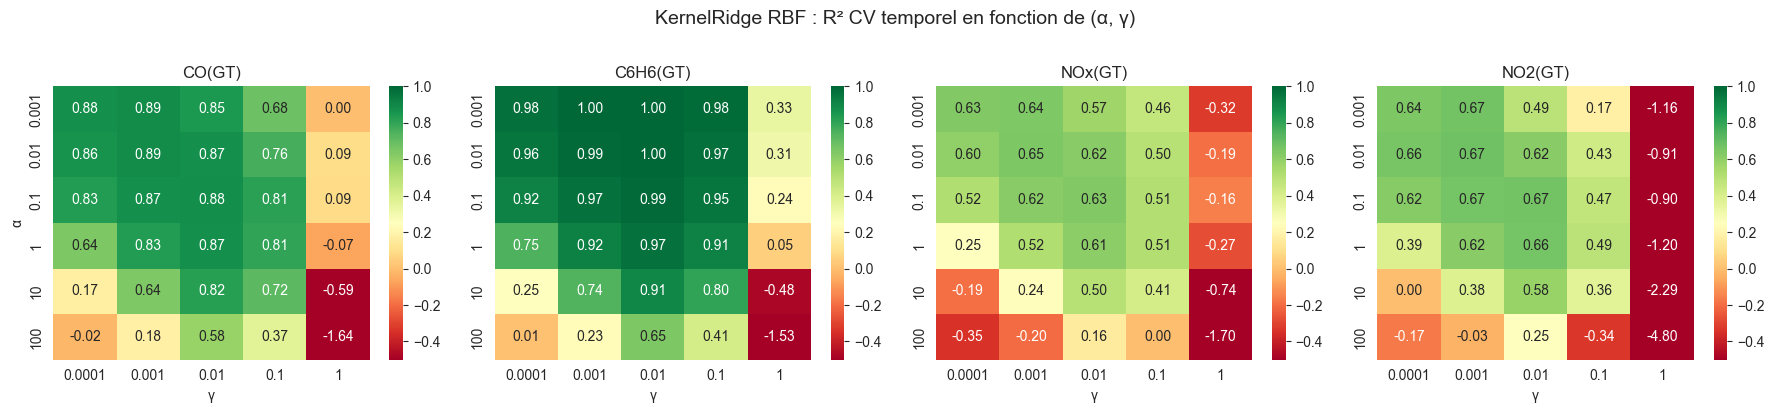

In [ ]:
# Relancer le GridSearch en stockant les résultats pour les heatmaps
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid_kr = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100],
    "gamma": [0.0001, 0.001, 0.01, 0.1, 1],
}

tscv = TimeSeriesSplit(n_splits=5)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for j, target in enumerate(targets):
    grid = GridSearchCV(
        KernelRidge(kernel="rbf"), param_grid_kr,
        scoring="r2", cv=tscv, n_jobs=-1,
    )
    grid.fit(X_train_s, ys_train[target])

    scores = grid.cv_results_["mean_test_score"].reshape(
        len(param_grid_kr["alpha"]), len(param_grid_kr["gamma"])
    )
    sns.heatmap(scores, annot=True, fmt=".2f", cmap="RdYlGn",
                xticklabels=param_grid_kr["gamma"],
                yticklabels=param_grid_kr["alpha"],
                ax=axes[j], vmin=-0.5, vmax=1)
    axes[j].set_title(target)
    axes[j].set_xlabel("γ")
    axes[j].set_ylabel("α" if j == 0 else "")

fig.suptitle("KernelRidge RBF : R² CV temporel en fonction de (α, γ)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


Sensitivity differs by pollutant. The near-perfect benzene score is a property of this dataset and protocol; agreement between validation and evaluation scores does not itself rule out leakage or overfitting.

## 4. Dense neural networks

The original `MLPRegressor` experiments use ReLU activations, Adam, L2 regularization and early stopping. Three architectures are compared. The internal early-stopping validation split is not a chronological validation protocol.

In [ ]:
from sklearn.neural_network import MLPRegressor

architectures = {
    "1 couche (64)": (64,),
    "2 couches (64, 32)": (64, 32),
    "3 couches (128, 64, 32)": (128, 64, 32),
}

nn_results = []

for target in targets:
    for name, arch in architectures.items():
        mlp = MLPRegressor(
            hidden_layer_sizes=arch,
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.15,
            random_state=42,
        )
        mlp.fit(X_train_s, ys_train[target])
        y_pred_train = mlp.predict(X_train_s)
        y_pred_test = mlp.predict(X_test_s)

        nn_results.append({
            "Cible": target,
            "Architecture": name,
            "R² (train)": round(r2_score(ys_train[target], y_pred_train), 4),
            "R² (test)": round(r2_score(ys_test[target], y_pred_test), 4),
            "RMSE (test)": round(np.sqrt(mean_squared_error(ys_test[target], y_pred_test)), 4),
            "MAE (test)": round(mean_absolute_error(ys_test[target], y_pred_test), 4),
            "Itérations": mlp.n_iter_,
        })

    print(f"{target} done")

pd.DataFrame(nn_results).set_index(["Cible", "Architecture"])


CO(GT) done
C6H6(GT) done
NOx(GT) done
NO2(GT) done


R² (train)  R² (test)  RMSE (test)  \
Cible    Architecture                                                  
CO(GT)   1 couche (64)                0.9206     0.8782       0.4564   
         2 couches (64, 32)           0.9413     0.8258       0.5458   
         3 couches (128, 64, 32)      0.9370     0.8621       0.4857   
C6H6(GT) 1 couche (64)                0.9969     0.9946       0.4617   
         2 couches (64, 32)           0.9993     0.9986       0.2383   
         3 couches (128, 64, 32)      0.9994     0.9981       0.2769   
NOx(GT)  1 couche (64)                0.9184     0.8847      64.6670   
         2 couches (64, 32)           0.9380     0.8961      61.3746   
         3 couches (128, 64, 32)      0.9475     0.8900      63.1690   
NO2(GT)  1 couche (64)                0.8501     0.6003      32.6033   
         2 couches (64, 32)           0.8544     0.6075      32.3087   
         3 couches (128, 64, 32)      0.8677     0.5763      33.5663   

                                  MAE (test)  Itérations  
Cible    Architecture                                     
CO(GT)   1 couche (64)                0.3028         142  
         2 couches (64, 32)           0.4003         194  
         3 couches (128, 64, 32)      0.3415          61  
C6H6(GT) 1 couche (64)                0.3598         118  
         2 couches (64, 32)           0.1813          81  
         3 couches (128, 64, 32)      0.1920          31  
NOx(GT)  1 couche (64)               43.4726         458  
         2 couches (64, 32)          43.2558         454  
         3 couches (128, 64, 32)     45.8457         305  
NO2(GT)  1 couche (64)               23.5715         364  
         2 couches (64, 32)          23.3377         185  
         3 couches (128, 64, 32)     24.3176         140

### 4.1 Learning-rate and regularization sensitivity

These heatmaps repeatedly evaluate configurations on the final chronological partition. They are exploratory diagnostics, not unbiased estimates for a model selected from the heatmap.

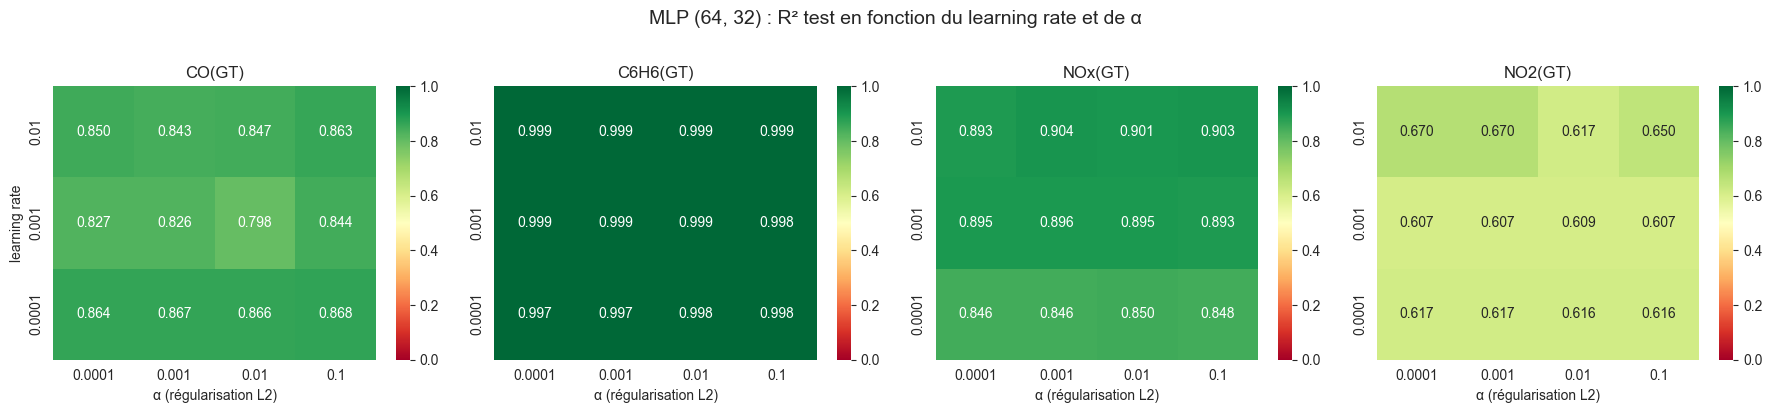

In [ ]:
lr_values = [0.01, 0.001, 0.0001]
alpha_values = [0.0001, 0.001, 0.01, 0.1]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for j, target in enumerate(targets):
    r2_matrix = np.zeros((len(lr_values), len(alpha_values)))
    for i, lr in enumerate(lr_values):
        for k, a in enumerate(alpha_values):
            mlp = MLPRegressor(
                hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                alpha=a, learning_rate_init=lr, max_iter=500,
                early_stopping=True, validation_fraction=0.15, random_state=42,
            )
            mlp.fit(X_train_s, ys_train[target])
            r2_matrix[i, k] = r2_score(ys_test[target], mlp.predict(X_test_s))

    sns.heatmap(r2_matrix, annot=True, fmt=".3f", cmap="RdYlGn",
                xticklabels=alpha_values, yticklabels=lr_values,
                ax=axes[j], vmin=0, vmax=1)
    axes[j].set_title(target)
    axes[j].set_xlabel("α (régularisation L2)")
    axes[j].set_ylabel("learning rate" if j == 0 else "")

fig.suptitle("MLP (64, 32) : R² test en fonction du learning rate et de α", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


### 4.2 Training curves

Training loss and internal validation scores show optimization behaviour for the tested architectures.

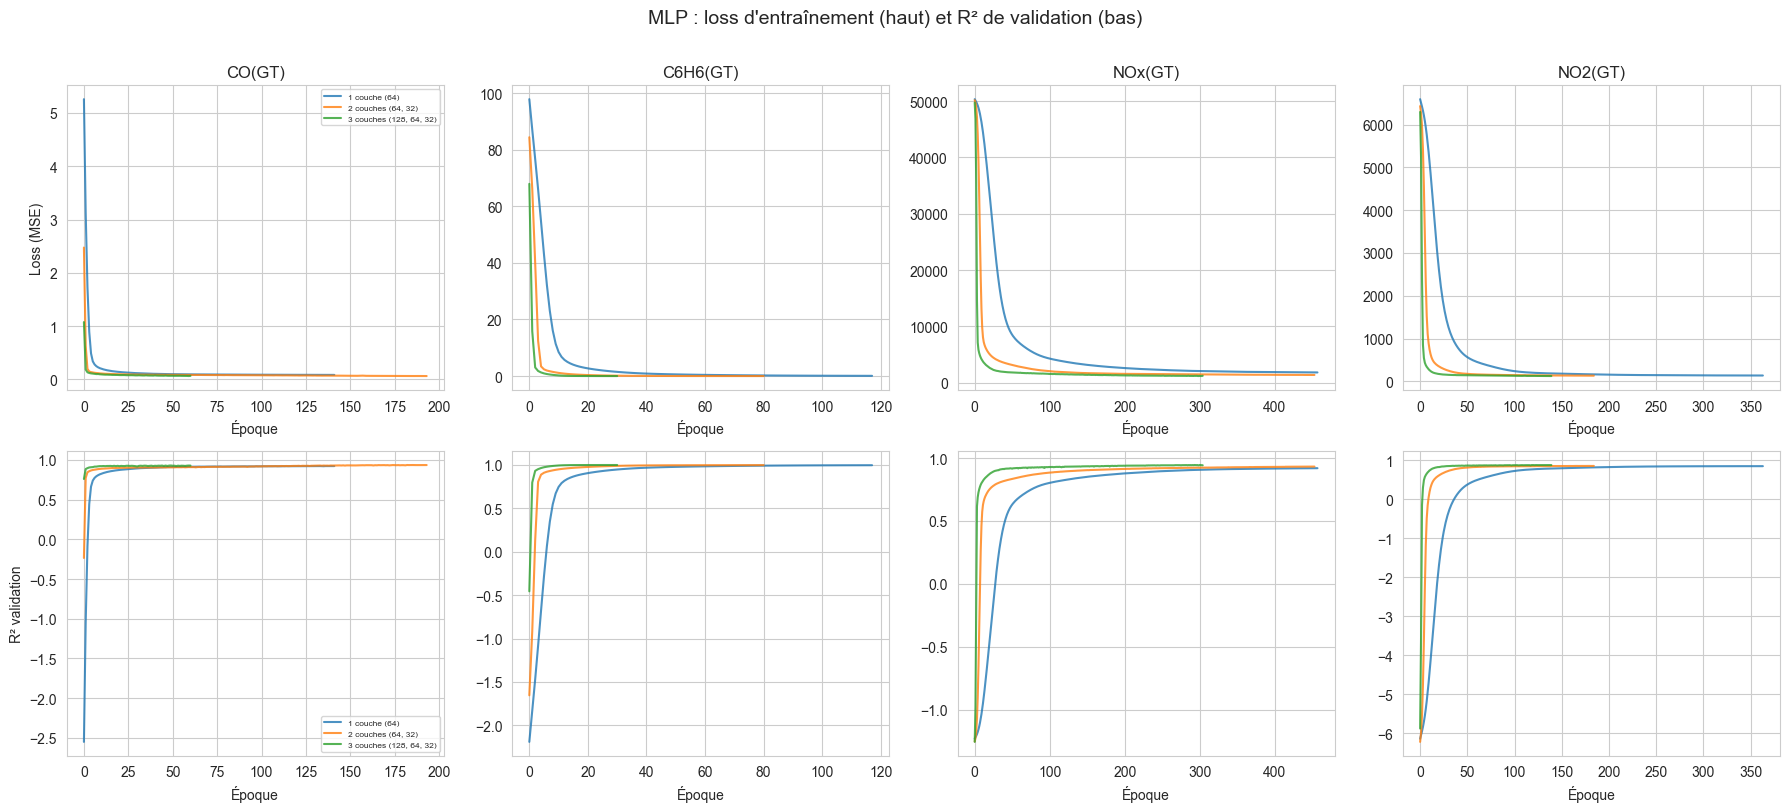

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for j, target in enumerate(targets):
    for name, arch in architectures.items():
        mlp = MLPRegressor(
            hidden_layer_sizes=arch, activation="relu", solver="adam",
            alpha=0.001, learning_rate_init=0.001, max_iter=500,
            early_stopping=True, validation_fraction=0.15, random_state=42,
        )
        mlp.fit(X_train_s, ys_train[target])
        axes[0, j].plot(mlp.loss_curve_, label=name, alpha=0.8)
        axes[1, j].plot(mlp.validation_scores_, label=name, alpha=0.8)

    axes[0, j].set_title(target)
    axes[0, j].set_xlabel("Époque")
    axes[0, j].set_ylabel("Loss (MSE)" if j == 0 else "")
    axes[1, j].set_xlabel("Époque")
    axes[1, j].set_ylabel("R² validation" if j == 0 else "")
    if j == 0:
        axes[0, j].legend(fontsize=6)
        axes[1, j].legend(fontsize=6)

fig.suptitle("MLP : loss d'entraînement (haut) et R² de validation (bas)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


The curves show how the fitted networks evolve during training. Similar plateaus do not prove that architecture, optimization or information content has been conclusively ruled out as a limiting factor.

### 4.3 Predicted versus observed concentrations

The displayed models are selected examples retained from the original notebook. Model selection has used the exploratory comparisons above.

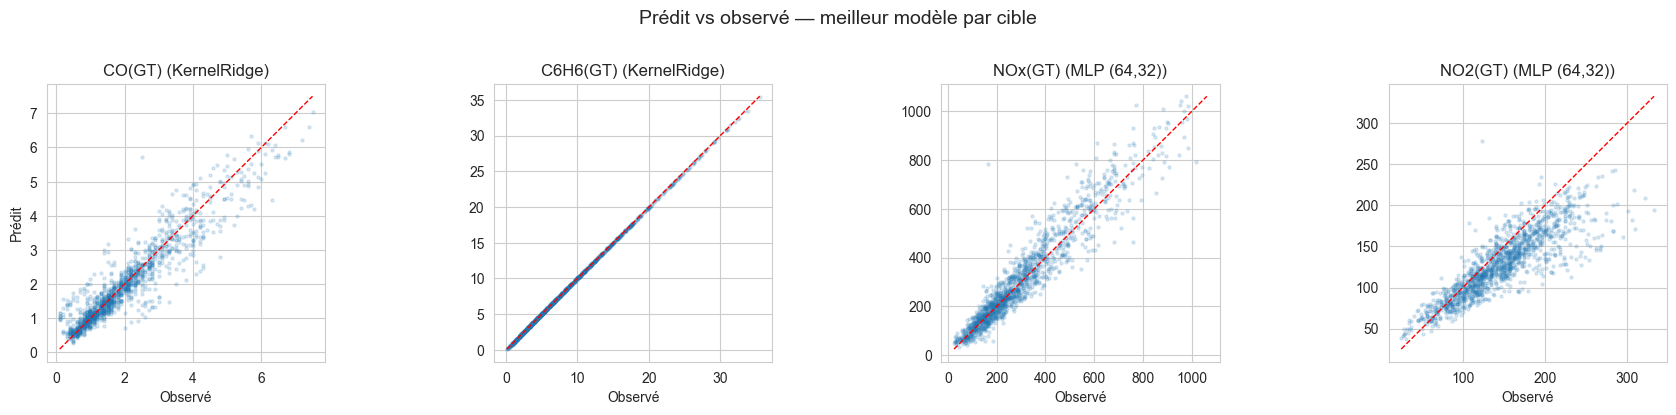

In [ ]:
# Meilleur modèle par cible : KernelRidge pour CO/C6H6, MLP pour NOx/NO2
best_models = {}
tscv = TimeSeriesSplit(n_splits=5)

for target in ["CO(GT)", "C6H6(GT)"]:
    kr = GridSearchCV(KernelRidge(kernel="rbf"), param_grid_kr, scoring="r2", cv=tscv, n_jobs=-1)
    kr.fit(X_train_s, ys_train[target])
    best_models[target] = ("KernelRidge", kr.best_estimator_)

for target in ["NOx(GT)", "NO2(GT)"]:
    mlp = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                        alpha=0.001, learning_rate_init=0.001, max_iter=500,
                        early_stopping=True, validation_fraction=0.15, random_state=42)
    mlp.fit(X_train_s, ys_train[target])
    best_models[target] = ("MLP (64,32)", mlp)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for j, target in enumerate(targets):
    method, model = best_models[target]
    y_pred = model.predict(X_test_s)
    y_true = ys_test[target]
    axes[j].scatter(y_true, y_pred, alpha=0.15, s=5)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    axes[j].plot(lims, lims, "r--", linewidth=1)
    axes[j].set_xlabel("Observé")
    axes[j].set_ylabel("Prédit" if j == 0 else "")
    axes[j].set_title(f"{target} ({method})")
    axes[j].set_aspect("equal", adjustable="box")

fig.suptitle("Prédit vs observé — meilleur modèle par cible", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


The scatter plots make errors at concentration extremes visible. Inspecting the full range complements aggregate R², RMSE and MAE.

### 4.4 Model interpretation

Permutation importance and Kernel SHAP summarize how these models use the inputs. They answer different attribution questions.

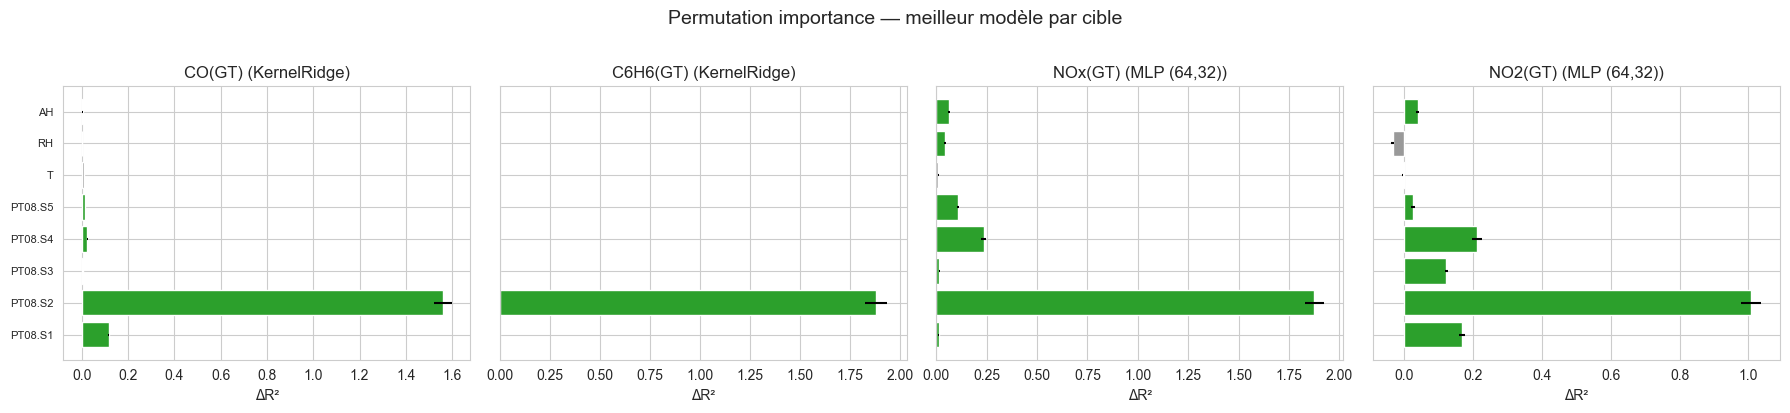

In [ ]:
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
short_names = [f.split("(")[0] for f in features]

for j, target in enumerate(targets):
    method, model = best_models[target]
    pi = permutation_importance(model, X_test_s, ys_test[target],
                                n_repeats=10, random_state=42, scoring="r2")

    colors = ["#2ca02c" if v > 0.01 else "#999999" for v in pi.importances_mean]
    axes[j].barh(range(len(features)), pi.importances_mean, xerr=pi.importances_std,
                 color=colors, edgecolor="white")
    axes[j].set_yticks(range(len(features)))
    axes[j].set_yticklabels(short_names if j == 0 else [], fontsize=8)
    axes[j].set_title(f"{target} ({method})")
    axes[j].set_xlabel("Î”R²")

fig.suptitle("Permutation importance — meilleur modèle par cible", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


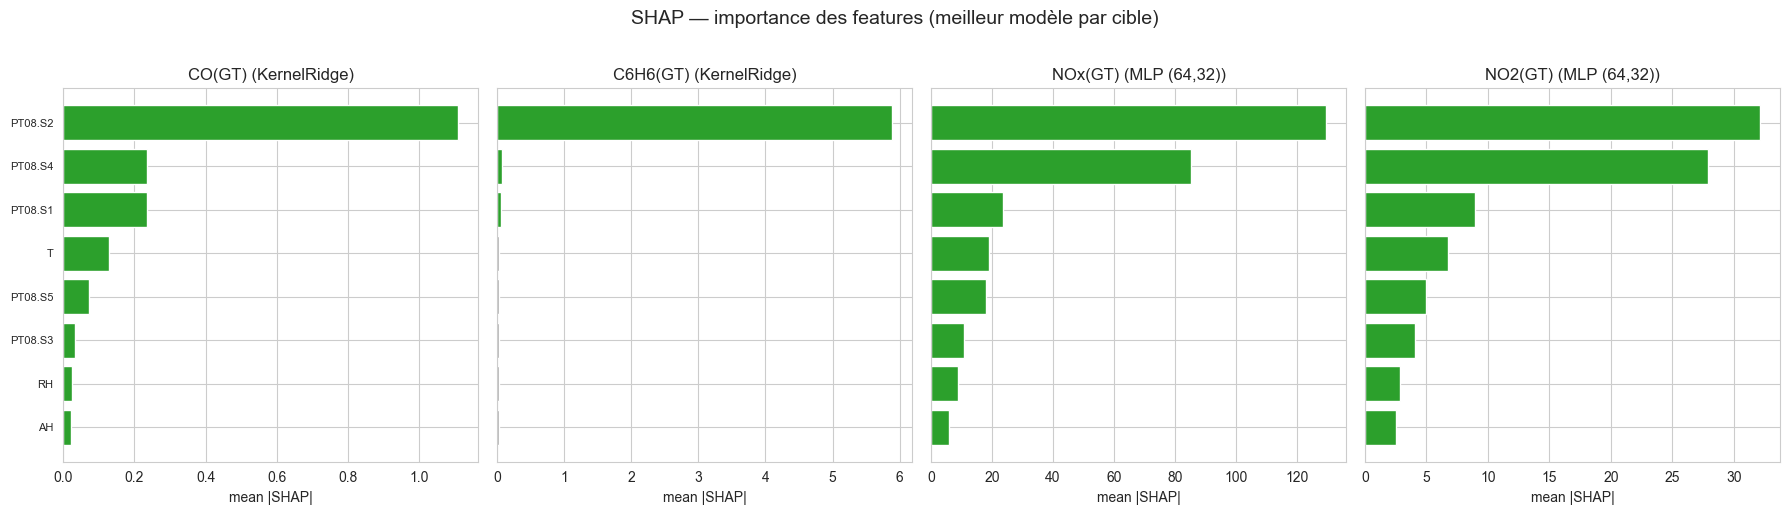

In [ ]:
import shap

background = shap.sample(X_train_s, 100, random_state=42)
X_explain = shap.sample(X_test_s, 200, random_state=42)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for j, target in enumerate(targets):
    method, model = best_models[target]
    explainer = shap.KernelExplainer(model.predict, background)
    shap_values = explainer.shap_values(X_explain, nsamples=100)

    mean_abs = np.abs(shap_values).mean(axis=0)
    order = np.argsort(mean_abs)
    colors = ["#2ca02c" if v > 0.01 * mean_abs.max() else "#999999" for v in mean_abs[order]]
    axes[j].barh(range(len(features)), mean_abs[order], color=colors, edgecolor="white")
    axes[j].set_yticks(range(len(features)))
    axes[j].set_yticklabels([short_names[i] for i in order] if j == 0 else [], fontsize=8)
    axes[j].set_title(f"{target} ({method})")
    axes[j].set_xlabel("mean |SHAP|")

fig.suptitle("SHAP — importance des features (meilleur modèle par cible)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


### 4.5 Reading feature attributions

Correlated sensors can produce unstable or ambiguous attributions. Kernel SHAP depends on its background sample and masking assumptions; it does not automatically resolve feature dependence or demonstrate a causal interaction. The two plots are complementary descriptive views.

### 4.6 Hour-of-day features

The existing experiment adds sine/cosine encodings of the hour to the NO2 model. Its configuration was chosen during the exploratory sweep.

In [ ]:
# --- Ajout de l'heure (sin/cos) pour NO2 ---

hour = df["Datetime"].dt.hour.values

# Encodage cyclique
hour_sin = np.sin(2 * np.pi * hour / 24)
hour_cos = np.cos(2 * np.pi * hour / 24)

# Ajout aux features
X_aug = np.column_stack([X, hour_sin, hour_cos])

X_aug_train, X_aug_test = X_aug[:split], X_aug[split:]

scaler_aug = StandardScaler()
X_aug_train_s = scaler_aug.fit_transform(X_aug_train)
X_aug_test_s = scaler_aug.transform(X_aug_test)

# Baseline sans heure (meilleur lr trouvé dans la heatmap)
mlp_base = MLPRegressor(
    hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
    alpha=0.0001, learning_rate_init=0.01, max_iter=500,
    early_stopping=True, validation_fraction=0.15, random_state=42,
)
mlp_base.fit(X_train_s, ys_train["NO2(GT)"])
r2_base = r2_score(ys_test["NO2(GT)"], mlp_base.predict(X_test_s))

# MLP sur NO2 avec features augmentées (même config)
mlp_aug = MLPRegressor(
    hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
    alpha=0.0001, learning_rate_init=0.01, max_iter=500,
    early_stopping=True, validation_fraction=0.15, random_state=42,
)
mlp_aug.fit(X_aug_train_s, ys_train["NO2(GT)"])
y_pred_test = mlp_aug.predict(X_aug_test_s)
r2_aug = r2_score(ys_test["NO2(GT)"], y_pred_test)

print("NO2 — MLP (64, 32), lr=0.01, α=0.0001")
print(f"Sans heure : R² test = {r2_base:.4f}")
print(f"Avec heure : R² test = {r2_aug:.4f}")
print(f"Gain       : +{r2_aug - r2_base:.4f}")
print(f"RMSE test  : {np.sqrt(mean_squared_error(ys_test['NO2(GT)'], y_pred_test)):.4f}")
print(f"MAE test   : {mean_absolute_error(ys_test['NO2(GT)'], y_pred_test):.4f}")


NO2 — MLP (64, 32), lr=0.01, α=0.0001
Sans heure : R² test = 0.6698
Avec heure : R² test = 0.7049
Gain       : +0.0351
RMSE test  : 28.0128
MAE test   : 20.2208


### 4.7 Residual diagnostics

The original residual experiment uses a deeper network `(256, 128, 64, 32)` with the augmented features.

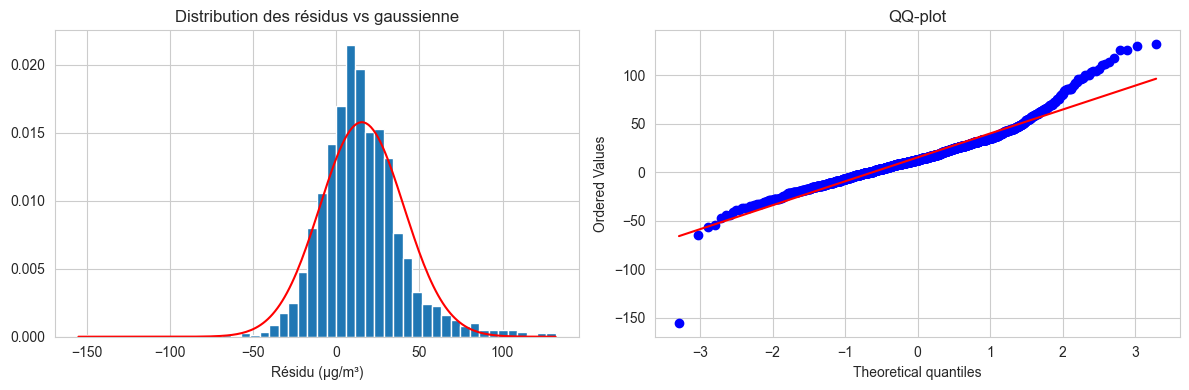

Moyenne : 15.41
Skewness : 0.68
Kurtosis : 3.58


In [ ]:
# Résidus du meilleur modèle MLP sur NO2
mlp_best = MLPRegressor(hidden_layer_sizes=(256, 128, 64, 32), activation="relu",
                         solver="adam", alpha=0.001, learning_rate_init=0.001,
                         max_iter=1000, early_stopping=True, validation_fraction=0.15,
                         random_state=42)
mlp_best.fit(X_aug_train_s, ys_train["NO2(GT)"])
residuals = ys_test["NO2(GT)"] - mlp_best.predict(X_aug_test_s)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(residuals, bins=50, edgecolor="white", density=True)
x_range = np.linspace(residuals.min(), residuals.max(), 200)
axes[0].plot(x_range, 1/(np.std(residuals)*np.sqrt(2*np.pi)) *
             np.exp(-0.5*((x_range-np.mean(residuals))/np.std(residuals))**2), 'r-')
axes[0].set_title("Distribution des résidus vs gaussienne")
axes[0].set_xlabel("Résidu (µg/m³)")

from scipy import stats
stats.probplot(residuals, plot=axes[1])
axes[1].set_title("QQ-plot")

plt.tight_layout()
plt.show()

print(f"Moyenne : {np.mean(residuals):.2f}")
print(f"Skewness : {stats.skew(residuals):.2f}")
print(f"Kurtosis : {stats.kurtosis(residuals):.2f}")


## 5. Findings and limits

The saved outputs show different levels of difficulty across pollutants. Linear models already perform well on some targets; nonlinear models capture additional structure. In the existing hour-of-day experiment, NO2 R² changes from **0.6698 to 0.7049** for the same MLP configuration. This is an exploratory observation from a reused evaluation partition.

The residual analysis uses another network architecture, so it is a separate diagnostic, not the error distribution of every MLP reported above. Its stored output shows a positive mean residual and a heavy right tail.

The original numerical runs are preserved. Narrative summary values have been aligned with their recorded outputs, without retraining models for this edition. [Full methodology and reproduction notes](../docs/methodology.md).